# Where do AI scribes fail? Analysis

**Set `DEMO = True`** to run on fake annotations (`python scripts/make_demo_annotations.py`)

In [1]:
DEMO = False

import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from src.common import ANN, OUT, load_config, load_traps, taxonomy_codes
from src import stats_utils as su

cfg = load_config()
CODES = taxonomy_codes()
ann_dir = ANN / "demo" if DEMO else ANN
(OUT / "tables").mkdir(parents=True, exist_ok=True); (OUT / "figures").mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3); pd.set_option("display.max_colwidth", 120)
if DEMO: print("*** DEMO MODE: fake annotations, do not report these numbers ***")

## 1. Data

In [2]:
h_notes, h_errs, h_traps = su.load_human("main", ann_dir)
H = su.note_level(h_notes, h_errs).merge(h_notes[["system", "encounter_id", "quality", "minutes"]], on=["system", "encounter_id"])
H["source"] = np.where(H.encounter_id.str.startswith("ED"), "synthetic_ed", "aci_bench")
SYSTEMS = [s["name"] for s in cfg["systems"] if s["name"] in set(H.system)]
print(f"{len(H)} reviewed notes, {len(h_errs)} human-logged errors, {H.minutes.sum()/60:.1f} h annotation")
H.groupby(["system", "source"]).size().unstack(fill_value=0)

40 reviewed notes, 42 human-logged errors, 62.0 h annotation


source,aci_bench,synthetic_ed
system,,
baseline,12,8
grounded,12,8


## 2. Error rates by system (physician labels)
Note-level rates with Wilson 95% CIs; errors per note with bootstrap CIs.

In [3]:
rows = []
for s in SYSTEMS:
    d = H[H.system == s]
    n = len(d)
    for col, label in [("any_error", "≥1 error (any severity)"), ("any_moderate_plus", "≥1 moderate or major error"),
                       ("any_critical", "≥1 major error")]:
        p, lo, hi = su.wilson(int(d[col].sum()), n)
        rows.append({"system": s, "metric": label, "estimate": p, "ci_low": lo, "ci_high": hi, "n": n})
    m, lo, hi = su.bootstrap_mean_ci(d.n_errors)
    rows.append({"system": s, "metric": "errors per note", "estimate": m, "ci_low": lo, "ci_high": hi, "n": n})
    m, lo, hi = su.bootstrap_mean_ci(d.quality)
    rows.append({"system": s, "metric": "quality (1-5)", "estimate": m, "ci_low": lo, "ci_high": hi, "n": n})
rates = pd.DataFrame(rows)
rates.to_csv(OUT / "tables/error_rates.csv", index=False)
rates.pivot(index="metric", columns="system", values="estimate")

system,baseline,grounded
metric,,
errors per note,1.85,0.25
quality (1-5),3.85,4.80
≥1 error (any severity),0.85,0.20
≥1 major error,0.00,0.00
≥1 moderate or major error,0.20,0.05


system,baseline,grounded
HALLUCINATION,0.70,0.10
OMISSION,0.05,0.05
NEGATION,0.00,0.00
NUMERIC_MED,0.00,0.00
MISATTRIBUTION,0.15,0.00
LATERALITY_LOCATION,0.00,0.00
TEMPORAL,0.00,0.00
CERTAINTY,0.00,0.00
SECTION,0.20,0.05
OTHER,0.00,0.00


severity,1,2
system,,
baseline,32,5
grounded,4,1


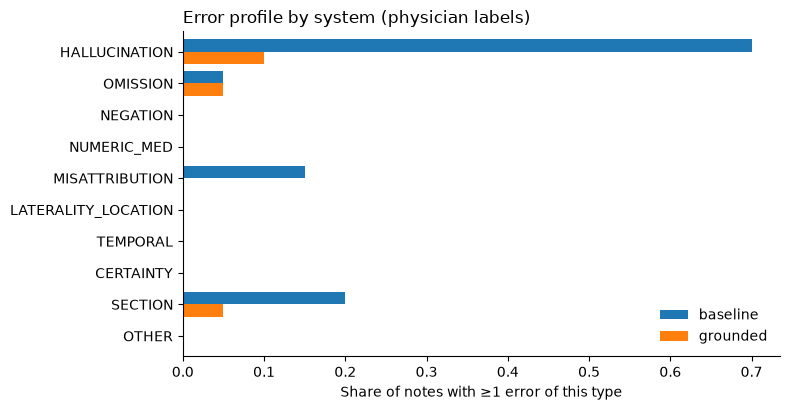

In [4]:
# Error profile: share of notes with at least one error of each category, by system
prof = H.groupby("system")[[f"cat_{c}" for c in CODES]].mean().T
prof.index = [i.replace("cat_", "") for i in prof.index]
prof = prof[SYSTEMS]
prof.to_csv(OUT / "tables/error_profile.csv")

# Severity mix
sev = h_errs.groupby(["system", "severity"]).size().unstack(fill_value=0).reindex(SYSTEMS)
display(prof.round(2)); display(sev)

fig, ax = plt.subplots(figsize=(8, 4.2))
prof.plot.barh(ax=ax, width=0.8)
ax.invert_yaxis(); ax.set_xlabel("Share of notes with ≥1 error of this type"); ax.set_ylabel("")
ax.legend(title="", frameon=False); ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Error profile by system (physician labels)", loc="left")
plt.tight_layout(); plt.savefig(OUT / "figures/error_profile.png", dpi=200); plt.show()

## 3. Ship decision: does the new prompt reduce errors?
Primary endpoint, reference, candidate and hypothesis are set in `config.yaml`.
Same model, same encounters, so the test is paired.
Decision test for superiority: exact one-sided McNemar test at the pre-specified alpha. The difference
is reported with a 95% Newcombe score interval (reliable with few discordant pairs, unlike a bootstrap).

In [5]:
dc = cfg["decision"]
ref, new, col = dc["reference_system"], dc["candidate_system"], dc["primary_endpoint"]
pw = su.paired(H, ref, new, col)
dec = su.decide(pw[ref], pw[new], dc.get("hypothesis", "superiority"),
                margin=dc.get("noninferiority_margin", 0.10), alpha=dc["alpha"])
print(f"Paired encounters: {len(pw)}")
print(f"{col}: {ref} = {pw[ref].mean():.3f}, {new} = {pw[new].mean():.3f}")
print(f"Discordant pairs: only {ref} had it = {dec['ref_only']}, only {new} had it = {dec['new_only']}")
print(f"Difference ({new} - {ref}) = {dec['diff_new_minus_ref']:+.3f}, 95% CI [{dec['ci95_low']:+.3f}, {dec['ci95_high']:+.3f}] (Newcombe)")
if dec["hypothesis"] == "superiority":
    print(f"Decision test: exact one-sided McNemar, p = {dec['p_one_sided_exact_mcnemar']:.3f} vs alpha = {dec['alpha_one_sided']}")
else:
    print(f"Decision test: {dec['ci_level']:.0%} CI upper bound {dec['ci_high']:+.3f} vs margin {dec['threshold']:+.2f}")
label = {"superiority": ("SUPERIOR: the new prompt reduces the primary endpoint", "Superiority NOT shown"),
         "noninferiority": ("NON-INFERIOR within the margin", "Non-inferiority NOT shown")}[dec["hypothesis"]]
print("=> " + (label[0] if dec["met"] else label[1]))
pd.DataFrame([{**dec, "ref": ref, "new": new, "endpoint": col, "n_pairs": len(pw)}]).to_csv(OUT / "tables/ship_decision.csv", index=False)

Paired encounters: 20
any_error: baseline = 0.850, grounded = 0.200
Discordant pairs: only baseline had it = 13, only grounded had it = 0
Difference (grounded - baseline) = -0.650, 95% CI [-0.787, -0.382] (Newcombe)
Decision test: exact one-sided McNemar, p = 0.000 vs alpha = 0.05
=> SUPERIOR: the new prompt reduces the primary endpoint


### 3a. Secondary endpoints
- **Errors per note:** uses every error, not just whether a note had one, so it has more power when most
  notes have zero or one error. Paired bootstrap CI for the mean difference and Wilcoxon signed-rank test.
- **≥1 moderate or major error** and **≥1 major error:** the clinically weighted views. 95% Newcombe CI and
  exact two-sided McNemar p.
All secondary p-values are two-sided and unadjusted; treat them as supporting evidence, not decisions.

In [6]:
sec = []
pw = su.paired(H, ref, new, "n_errors")
d, lo, hi = su.paired_diff_ci(pw[ref], pw[new])
sec.append({"endpoint": "errors per note", ref: pw[ref].mean(), new: pw[new].mean(), "diff_new_minus_ref": d,
            "ci_low": lo, "ci_high": hi, "test": "Wilcoxon", "p_value": su.wilcoxon_paired(pw[ref], pw[new]), "n_pairs": len(pw)})
for c, lab in [("any_moderate_plus", "≥1 moderate or major error"), ("any_critical", "≥1 major error")]:
    pw = su.paired(H, ref, new, c)
    d, lo, hi = su.newcombe_paired_ci(pw[ref], pw[new])
    sec.append({"endpoint": lab, ref: pw[ref].mean(), new: pw[new].mean(), "diff_new_minus_ref": d,
                "ci_low": lo, "ci_high": hi, "test": "McNemar exact", "p_value": su.mcnemar_exact(pw[ref], pw[new])["p_value"],
                "n_pairs": len(pw)})
SEC = pd.DataFrame(sec); SEC.to_csv(OUT / "tables/secondary_endpoints.csv", index=False); SEC

,endpoint,baseline,grounded,diff_new_minus_ref,ci_low,ci_high,test,p_value,n_pairs
0,errors per note,1.85,0.25,-1.60,-2.050,-1.150,Wilcoxon,2.415e-04,20
1,≥1 moderate or major error,0.20,0.05,-0.15,-0.351,0.019,McNemar exact,2.500e-01,20
2,≥1 major error,0.00,0.00,0.00,-0.161,0.161,McNemar exact,1.000e+00,20


### 3b. What did the prompt change? Category-level trade-offs
Paired differences in the share of notes with each error type (candidate minus reference).
Look for a trade-off: rules like "never add anything not stated" may cut hallucinations but
make the model more conservative, which can raise omissions. Exploratory, not adjusted for multiplicity.

,category,baseline,grounded,diff,ci_low,ci_high,mcnemar_p
0,HALLUCINATION,0.70,0.10,-0.60,-0.756,-0.337,4.883e-04
3,SECTION,0.20,0.05,-0.15,-0.374,0.082,3.750e-01
2,MISATTRIBUTION,0.15,0.00,-0.15,-0.360,0.038,2.500e-01
1,OMISSION,0.05,0.05,0.00,-0.193,0.193,1.000e+00


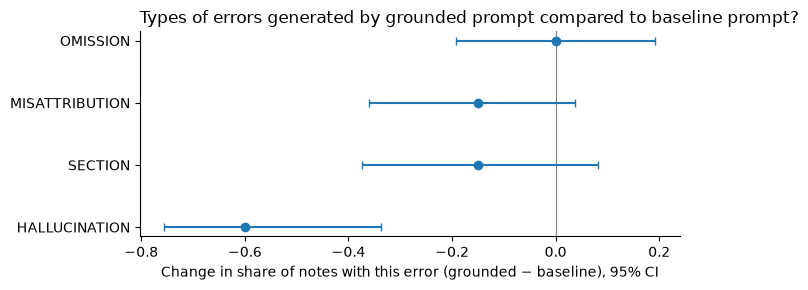

In [16]:
rows = []
for c in CODES:
    pw_c = su.paired(H, ref, new, f"cat_{c}")
    if pw_c[[ref, new]].values.sum() == 0:
        continue
    d, lo, hi = su.newcombe_paired_ci(pw_c[ref], pw_c[new])
    rows.append({"category": c, ref: pw_c[ref].mean(), new: pw_c[new].mean(), "diff": d, "ci_low": lo, "ci_high": hi,
                 "mcnemar_p": su.mcnemar_exact(pw_c[ref], pw_c[new])["p_value"]})
CAT = pd.DataFrame(rows).sort_values("diff")
CAT.to_csv(OUT / "tables/prompt_effect_by_category.csv", index=False)
display(CAT)

fig, ax = plt.subplots(figsize=(7, 0.45 * len(CAT) + 1.2))
ax.axvline(0, color="gray", lw=0.8)
ax.errorbar(CAT["diff"], CAT.category, xerr=[CAT["diff"] - CAT.ci_low, CAT.ci_high - CAT["diff"]], fmt="o", capsize=3)
ax.set_xlabel(f"Change in share of notes with this error ({new} − {ref}), 95% CI")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Types of errors generated by grounded prompt compared to baseline prompt?", loc="left")
plt.tight_layout(); plt.savefig(OUT / "figures/prompt_effect_by_category.png", dpi=200); plt.show()

In [8]:
# Note length and cost by system (longer notes take longer to review before signing)
from src.common import read_jsonl
N = pd.DataFrame(read_jsonl(OUT / "notes.jsonl"))
N["words"] = N.note.str.split().str.len()
N.groupby("system")[["words", "input_tokens", "output_tokens", "latency_s"]].mean().reindex(SYSTEMS).round(1)

,words,input_tokens,output_tokens,latency_s
system,,,,
baseline,448.0,1982.0,1188.9,8.7
grounded,488.7,2782.0,2130.6,15.2


In [ ]:
# # Optional verify arm: how much did the self-audit pass change the draft?
# if "draft_note" in N and N.draft_note.notna().any():
#     import difflib
#     V = N[N.draft_note.notna()].copy()
#     V["similarity_to_draft"] = [difflib.SequenceMatcher(None, a, b).ratio() for a, b in zip(V.draft_note, V.note)]
#     V["words_added"] = V.words - V.draft_note.str.split().str.len()
#     display(V.groupby("system")[["similarity_to_draft", "words_added"]].describe().round(2))
# else:
#     print("No verify arm in this run.")

In [9]:
# All pairwise comparisons (exploratory; not multiplicity-adjusted)
out = []
for i, a in enumerate(SYSTEMS):
    for b in SYSTEMS[i + 1:]:
        for c in ["any_error", "any_moderate_plus", "any_critical"]:
            pw2 = su.paired(H, a, b, c)
            d, lo, hi = su.newcombe_paired_ci(pw2[a], pw2[b])
            out.append({"a": a, "b": b, "endpoint": c, "n": len(pw2), "diff_b_minus_a": d, "ci_low": lo, "ci_high": hi,
                        "mcnemar_p": su.mcnemar_exact(pw2[a], pw2[b])["p_value"]})
pd.DataFrame(out)

,a,b,endpoint,n,diff_b_minus_a,ci_low,ci_high,mcnemar_p
0,baseline,grounded,any_error,20,-0.65,-0.787,-0.382,2.441e-04
1,baseline,grounded,any_moderate_plus,20,-0.15,-0.351,0.019,2.500e-01
2,baseline,grounded,any_critical,20,0.00,-0.161,0.161,1.000e+00


## 4. Synthetic ED trap checklist
Each trap is one pre-specified clinical fact; pass rate per system and per trap category.

In [10]:
traps = load_traps(cfg)
T = h_traps[h_traps.result.isin(["pass", "fail"])].merge(traps[["trap_id", "category", "check"]], on="trap_id")
if T.empty:
    print("No trap results yet.")
else:
    T["passed"] = (T.result == "pass").astype(int)
    by_sys = T.groupby("system").passed.agg(["mean", "sum", "count"]).reindex(SYSTEMS)
    by_sys[["ci_low", "ci_high"]] = [su.wilson(int(r["sum"]), int(r["count"]))[1:] for _, r in by_sys.iterrows()]
    display(by_sys)
    display(T.pivot_table(index="category", columns="system", values="passed", aggfunc="mean")[SYSTEMS].round(2))
    fails = T[T.result == "fail"].sort_values(["trap_id", "system"])[["trap_id", "system", "check"]]
    fails.to_csv(OUT / "tables/trap_failures.csv", index=False)
    display(fails)

,mean,sum,count,ci_low,ci_high
system,,,,,
baseline,1.0,62,62,0.942,1.0
grounded,1.0,62,62,0.942,1.0


system,baseline,grounded
category,,
CERTAINTY,1.0,1.0
HALLUCINATION,1.0,1.0
LATERALITY_LOCATION,1.0,1.0
MISATTRIBUTION,1.0,1.0
NEGATION,1.0,1.0
NUMERIC_MED,1.0,1.0
OMISSION,1.0,1.0
OTHER,1.0,1.0
TEMPORAL,1.0,1.0


,trap_id,system,check


## 5. Do automated metrics track clinical errors?
ACI-Bench encounters only (they have reference notes). If ROUGE barely correlates with
physician-judged errors, that's a headline finding.

,metric,vs,spearman_rho,p,n
0,rouge1,n_errors,-0.062,0.773,24
1,rouge1,n_moderate_plus,0.056,0.794,24
2,rouge1,quality,0.125,0.560,24
3,rouge2,n_errors,-0.004,0.985,24
4,rouge2,n_moderate_plus,0.103,0.631,24
5,rouge2,quality,0.051,0.814,24
6,rougeL,n_errors,-0.033,0.877,24
7,rougeL,n_moderate_plus,0.054,0.801,24
8,rougeL,quality,0.092,0.667,24


,mean_rougeL,any_error_rate,quality
system,,,
baseline,0.348,0.750,4.083
grounded,0.323,0.083,4.917


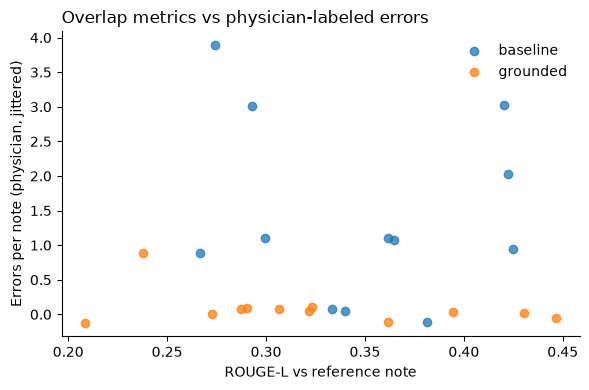

In [11]:
am_path = OUT / "auto_metrics.csv"
if am_path.exists():
    am = pd.read_csv(am_path).merge(H, on=["system", "encounter_id"])
    metric_cols = [c for c in ["rouge1", "rouge2", "rougeL", "bertscore_f1"] if c in am]
    corr = []
    for m in metric_cols:
        for target in ["n_errors", "n_moderate_plus", "quality"]:
            rho, p = spearmanr(am[m], am[target])
            corr.append({"metric": m, "vs": target, "spearman_rho": rho, "p": p, "n": len(am)})
    corr = pd.DataFrame(corr); corr.to_csv(OUT / "tables/metric_correlations.csv", index=False)
    display(corr)
    # Do metric-based and clinician-based system rankings agree?
    rank = pd.DataFrame({"mean_rougeL": am.groupby("system").rougeL.mean(),
                         "any_error_rate": am.groupby("system").any_error.mean(),
                         "quality": am.groupby("system").quality.mean()}).reindex(SYSTEMS)
    display(rank)
    fig, ax = plt.subplots(figsize=(6, 4))
    for s in SYSTEMS:
        d = am[am.system == s]
        ax.scatter(d.rougeL, d.n_errors + np.random.default_rng(0).uniform(-.12, .12, len(d)), label=s, alpha=.75)
    ax.set_xlabel("ROUGE-L vs reference note"); ax.set_ylabel("Errors per note (physician, jittered)")
    ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
    ax.set_title("Overlap metrics vs physician-labeled errors", loc="left")
    plt.tight_layout(); plt.savefig(OUT / "figures/rouge_vs_errors.png", dpi=200); plt.show()
else:
    print("Run `python -m src.auto_metrics` first.")

## 6. Can the LLM judge be trusted?
Physician labels are the reference standard. Report kappa, and sensitivity / PPV for
errors of each severity: that's what decides whether a judge could replace human review.

In [12]:
j_notes, j_errs = su.load_judge()
print(f"Judge status counts: {j_notes.status.value_counts().to_dict()}")
J = su.note_level(j_notes[j_notes.status == "ok"], j_errs)
M = H.merge(J, on=["system", "encounter_id"], suffixes=("_h", "_j"))
print(f"{len(M)} notes labeled by both")

ag = [{"level": "note", "target": t, **su.agreement(M[f"{t}_h"], M[f"{t}_j"])} for t in ["any_error", "any_moderate_plus", "any_critical"]]
ag += [{"level": "category", "target": c, **su.agreement(M[f"cat_{c}_h"], M[f"cat_{c}_j"])} for c in CODES]
AG = pd.DataFrame(ag)
AG.to_csv(OUT / "tables/judge_agreement.csv", index=False)
AG[["level", "target", "n", "prevalence", "kappa", "sensitivity", "sens_lo", "sens_hi", "ppv", "ppv_lo", "ppv_hi", "specificity"]]

Judge status counts: {'ok': 96}
40 notes labeled by both


,level,target,n,prevalence,kappa,sensitivity,sens_lo,sens_hi,ppv,ppv_lo,ppv_hi,specificity
0,note,any_error,40,0.525,0.163,0.429,2.447e-01,0.635,0.643,0.388,0.837,0.737
1,note,any_moderate_plus,40,0.125,0.094,0.400,1.176e-01,0.769,0.182,0.051,0.477,0.743
2,note,any_critical,40,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000
3,category,HALLUCINATION,40,0.400,0.138,0.250,1.018e-01,0.495,0.571,0.250,0.842,0.875
4,category,OMISSION,40,0.050,0.474,0.500,9.453e-02,0.905,0.500,0.095,0.905,0.974
5,category,NEGATION,40,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000
6,category,NUMERIC_MED,40,0.000,0.000,NaN,NaN,NaN,0.000,0.000,0.793,0.975
7,category,MISATTRIBUTION,40,0.075,-0.039,0.000,5.551e-17,0.561,0.000,0.000,0.793,0.973
8,category,LATERALITY_LOCATION,40,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000
9,category,TEMPORAL,40,0.000,0.000,NaN,NaN,NaN,0.000,0.000,0.434,0.875


In [13]:
# Does the judge rank systems the same way the physician does? (Judge bias by system)
cmp = pd.DataFrame({
    "human_any_error_rate": M.groupby("system").any_error_h.mean(),
    "judge_any_error_rate": M.groupby("system").any_error_j.mean(),
    "human_major_rate": M.groupby("system").any_critical_h.mean(),
    "judge_major_rate": M.groupby("system").any_critical_j.mean(),
    "human_errors_per_note": M.groupby("system").n_errors_h.mean(),
    "judge_errors_per_note": M.groupby("system").n_errors_j.mean(),
}).reindex(SYSTEMS)
cmp.to_csv(OUT / "tables/judge_vs_human_by_system.csv"); cmp

,human_any_error_rate,judge_any_error_rate,human_major_rate,judge_major_rate,human_errors_per_note,judge_errors_per_note
system,,,,,,
baseline,0.85,0.55,0.0,0.0,1.85,0.75
grounded,0.20,0.15,0.0,0.0,0.25,0.15


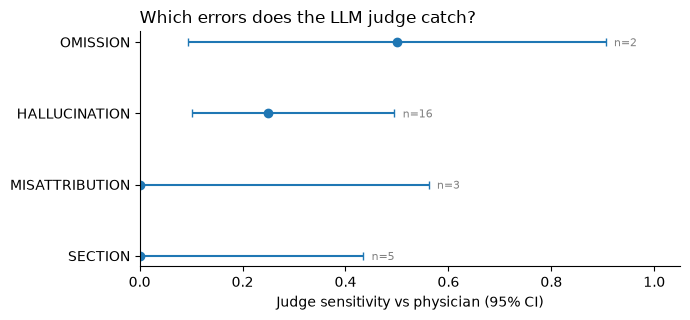

In [14]:
# Per-category sensitivity with CIs (the chart for the write-up)
cat = AG[(AG.level == "category") & ((AG.tp + AG.fn) > 0)].sort_values("sensitivity")
if cat.empty:
    print("No physician-labeled errors in any category yet; nothing to plot.")
else:
  fig, ax = plt.subplots(figsize=(7, 0.45 * len(cat) + 1.5))
  err_lo = (cat.sensitivity - cat.sens_lo).clip(lower=0); err_hi = (cat.sens_hi - cat.sensitivity).clip(lower=0)
  ax.errorbar(cat.sensitivity, cat.target, xerr=[err_lo, err_hi], fmt="o", capsize=3)
  for _, r in cat.iterrows():
      ax.annotate(f"n={r.tp + r.fn}", (r.sens_hi, r.target), xytext=(6, -3), textcoords="offset points", fontsize=8, color="gray")
  ax.set_xlim(0, 1.05); ax.set_xlabel("Judge sensitivity vs physician (95% CI)")
  ax.spines[["top", "right"]].set_visible(False); ax.set_title("Which errors does the LLM judge catch?", loc="left")
  plt.tight_layout(); plt.savefig(OUT / "figures/judge_sensitivity_by_category.png", dpi=200); plt.show()

## 7. Intra-rater reliability
Re-labeled subset (Day 3), same rater, blinded to first-pass labels.

In [ ]:
# try:
#     r_notes, r_errs, _ = su.load_human("relabel", ann_dir)
#     R = su.note_level(r_notes, r_errs)
#     RR = H.merge(R, on=["system", "encounter_id"], suffixes=("_1", "_2"))
#     irr = [{"target": t, **su.agreement(RR[f"{t}_1"], RR[f"{t}_2"])} for t in ["any_error", "any_moderate_plus", "any_critical"]]
#     irr += [{"target": c, **su.agreement(RR[f"cat_{c}_1"], RR[f"cat_{c}_2"])} for c in CODES if RR[[f"cat_{c}_1", f"cat_{c}_2"]].values.any()]
#     IRR = pd.DataFrame(irr)[["target", "n", "prevalence", "kappa", "tp", "fp", "fn", "tn"]]
#     IRR.to_csv(OUT / "tables/intra_rater.csv", index=False); display(IRR)
# except FileNotFoundError as e:
#     print("No re-label set yet:", e)

## 8. Failure gallery
All errors with evidence, most severe first: pick 3 to 5 for the write-up and add your clinical commentary.

In [15]:
gal = h_errs.copy()
jflag = j_errs.assign(j=1).groupby(["system", "encounter_id", "category"]).j.max().reset_index()
gal = gal.merge(jflag, how="left", on=["system", "encounter_id", "category"]).fillna({"j": 0})
gal["judge_caught_same_category"] = gal.j.astype(int)
cols = ["system", "encounter_id", "severity", "category", "note_text", "transcript_evidence", "comment", "judge_caught_same_category"]
gal = gal[cols].sort_values(["severity", "category", "system"], ascending=[False, True, True])
gal.to_csv(OUT / "tables/error_gallery.csv", index=False)
gal.head(40)

,system,encounter_id,severity,category,note_text,transcript_evidence,comment,judge_caught_same_category
8,baseline,D2N110,2,HALLUCINATION,**PAST MEDICAL HISTORY**\nDiabetes mellitus\nDiabetic neuropathy,[patient] no i bought a new pair of shoes to travel with and the neuropathy i guess i did n't feel that they were to...,"Diabetic neuropathy is never established; pt mentions neuropathy, but this is never explicitly linked to Diabetes",0
28,baseline,ED01,2,HALLUCINATION,"Chest pressure, concerning for a cardiac etiology (possible acute coronary syndrome).","i'm concerned this could be your heart,",Possible ACS never specified by physician,0
36,baseline,ED03,2,HALLUCINATION,imaging is indicated per Ottawa ankle rules,NaN,Physician never mentions Ottawa ankle rules; this is complete fabrication,0
38,baseline,D2N113,2,HALLUCINATION,No known hepatitis C-positive partners were reported,[doctor] okay and do do you have any history like iv drug use known that you know or do you have any known to have a...,Patient never responds to the question about Hep C positive partners,0
39,baseline,D2N113,2,OMISSION,Abdomen: Bowel sounds present. Soft. No splenomegaly appreciated.,abdomen is soft with no hepatospleno splenomegaly,"Physician documents no hepatosplenomegaly, but note only states no splenomegaly",1
2,grounded,ED01,2,OMISSION,Denies radiation to the arm.,"[doctor] does the pressure go anywhere, like your arm, jaw, or back?\n[patient] no, it doesn't go to my arm or anyth...",Omitted: no radiation to jaw or back,0
0,baseline,ED04,1,HALLUCINATION,Sumatriptan 50 mg as needed (taken twice yesterday).,"[patient] i took my sumatriptan, fifty milligrams, twice yesterday.","Prescribed frequency of ""as needed"" is not specified in transcript",0
1,baseline,ED04,1,HALLUCINATION,RESULTS\nUrine pregnancy test ordered; result not yet available.,we'll check a pregnancy test,Pregnancy test is part of the plan; has not yet been ordered,0
5,baseline,D2N109,1,HALLUCINATION,"Ibuprofen (OTC, recent use for ankle pain)",[doctor] sure have you tried anything for pain or the swelling or anything like that\n[patient] ibuprofen some ice a...,"Note specifies ibuprofen OTC, but OTC is not supported by transcript",0
7,baseline,D2N110,1,HALLUCINATION,- Consider a diabetic (nutrition) consult for dietary modifications,we might even go ahead and get a diabetic consult so that we can go over some some maybe some ways you can modify yo...,Transcript doesn't specify that the consult is to a nutritionist,0


## 9. Notes for the write-up
- Report n for every estimate; with 20 pairs, CIs are wide. Say so.
- The primary endpoint is ≥1 error of any severity
- The judge's failure modes (section 6) and the metric/clinical disagreement (section 5) are
  usually the most interesting findings for a documentation-AI team.